In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as snb
from tqdm import tqdm 
import os


# Data Import 

In [2]:
DATA_LOADING_BENCHMARK_CSV = r"C:\Users\marou\Desktop\Uni\HPC\Projekt\code\jobs\data_loading_benchmark\_benchmark\data_loading\data_loading_benchmark.csv"
df = pd.read_csv(DATA_LOADING_BENCHMARK_CSV)


# DataLoader Benchmark Metrics

When benchmarking PyTorch `DataLoader` with multiple workers, we can evaluate **three key metrics**:

---

### 1. **Speedup** ($S_n$)

$$
S_n = \frac{T_1}{T_n}
$$

- How much faster the DataLoader runs with `n` workers compared to 1 worker.  
- **$S_n = 1$** → no speedup; **$S_n \approx n$** → perfect linear scaling.

---

### 2. **Efficiency** ($E_n$)

$$
E_n = \frac{S_n}{n}
$$

- Fraction of theoretical performance achieved per worker.  
- **$E_n = 1$** → perfect use of resources; drops with overhead or contention.

---

### 3. **Compute Performance / Throughput** ($P_n$)

$$
P_n = \frac{\text{work}}{T_n}
$$

- Work done per unit of time (e.g., images/ms).  
- Higher is better; shows absolute processing speed regardless of speedup.

---

### 🧠 How to Interpret Together

- **Speedup** → does adding workers reduce runtime?  
- **Efficiency** → are extra workers being effectively used?  
- **Compute Performance** → how fast is data actually processed?  



# calculate speedup and compute performance

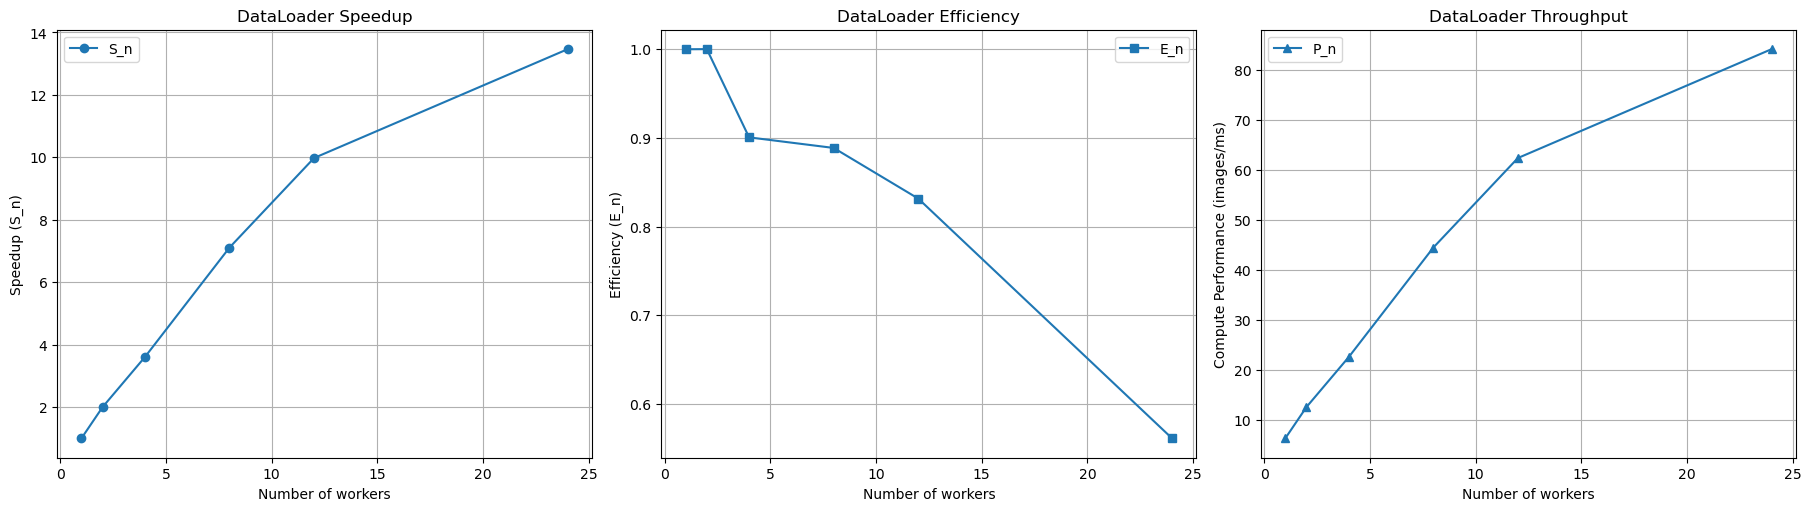

In [3]:
# Define total work (number of images processed)
work = 60000  # full FashionMNIST dataset

# Aggregate runtimes per number of workers
df_stats = df.groupby("num_workers")["runtime_ms"].mean().to_frame("T_n")


# Calculate Speedup S_n = T1 / Tn
T1 = df_stats.loc[1, "T_n"]
df_stats["S_n"] = T1 / df_stats["T_n"]

# Calculate Efficiency E_n = S_n / n
df_stats["E_n"] = df_stats["S_n"] / df_stats.index

# Compute Performance P_n = work / Tn (images per millisecond)
df_stats["P_n"] = work / df_stats["T_n"]

# Plot metrics
fig, axes = plt.subplots(1, 3, figsize=(18,5), layout="constrained")

# Speedup
df_stats["S_n"].plot(marker="o", ax=axes[0], grid=True)
x = df_stats.index.values  # number of workers
axes[0].set_xlabel("Number of workers")
axes[0].set_ylabel("Speedup (S_n)")
axes[0].set_title("DataLoader Speedup")
axes[0].legend()

# Efficiency
df_stats["E_n"].plot(marker="s", ax=axes[1], grid=True)
axes[1].set_xlabel("Number of workers")
axes[1].set_ylabel("Efficiency (E_n)")
axes[1].set_title("DataLoader Efficiency")
axes[1].legend()

# Compute Performance
df_stats["P_n"].plot(marker="^", ax=axes[2], grid=True)
axes[2].set_xlabel("Number of workers")
axes[2].set_ylabel("Compute Performance (images/ms)")
axes[2].set_title("DataLoader Throughput")
axes[2].legend()

plt.show()
